# Paper 15 — Directing a Voice Performance

## Abstract
This notebook tests how to direct local synthetic speech as a performance: rhythm, emphasis, pauses, pitch variation and emotional delivery. It compares written direction with a fixed voice reference in full VoxCPM2 against same-speaker expressive references in F5. Mastering is excluded from the primary performance comparison. No subjective winner or reliable emotion control is presumed.

## Questions and hypotheses
**H1:** With the same text, seed and neutral reference, changing VoxCPM2 delivery instructions can produce distinguishable, appropriate performances without losing words or speaker continuity.

**H2:** F5's expressive references can produce useful delivery variation for the same speaker; reference content and delivery are confounded and must be reported.

**H3:** Delivery transfers across two differently worded, emotionally ambiguous lines rather than merely exploiting emotional wording.

Failures include unchanged delivery despite instructions, exaggerated or inappropriate acting, missing words, unstable identity, clipping, silence and unacceptable latency. Signal measurements are diagnostic clues and do not establish convincing acting.

## Bounded design
Two existing speaker references (male and female), four directions (neutral, excited, restrained anger, reflective sadness), two texts, and two engines: 32 planned takes. Seed is fixed at 42. This is an exploratory pilot with no independent listener panel or seed-robustness claim. VoxCPM2 holds its neutral identity reference fixed and varies written direction. F5 varies same-speaker emotion references. Their sampling controls and reference mechanisms differ, so this is a practical directing comparison rather than an isolated model-quality benchmark.

## Listening rubric
Score each take only after listening: exact words, intended delivery, believable performance, identity continuity, and artifacts. Use 1–5 for subjective items and record skipped/extra words separately. Compare neutral and expressive takes at matched loudness; do not use loudness as a substitute for acting. Listener scores remain blank until actually assessed.

**Status: all 32 planned takes generated and technically checked. Matched auditions are embedded below. Perceptual performance hypotheses remain unscored.**


In [1]:
from pathlib import Path
import json
from IPython.display import Audio, display
STUDY = Path('/Users/x/projects/swarms/knowledge/research/paper-15-study')
plan = json.loads((STUDY/'plan.json').read_text())
print(len(plan['conditions']), 'paired conditions;', 2*len(plan['conditions']), 'planned takes')

16 paired conditions; 32 planned takes


## Supported control paths and limits
The pinned VoiceStudio adapter forwards VoxCPM2 written direction as an inline control prefix and supplies the reference as its native reference waveform. Supplying a delivery instruction selects controllable cloning rather than transcript continuation. Reference audio is silence-trimmed by the adapter. There is no verified phoneme-by-phoneme pitch, timing or emotion trajectory controller in this experiment. Written direction is a request to the model, not a guaranteed acting specification.

F5 uses the existing same-speaker ESD emotion references and their transcripts. Its engine settings are fixed at 32 sampling steps, speed 1, guidance 2, sway −1, crossfade 0.15 seconds, seed 42. VoxCPM2 uses 10 steps, guidance 2 and seed 42. VoiceStudio's application effects are raw; its synthetic watermark remains enabled. F5's source recordings have existing reference preparation, and engine-internal processing differs. These differences remain confounds.

## Runnable experiment
The following functions launch the actual serial audition and analysis scripts. They are defined without automatically generating all recordings on notebook open. Completed takes are preserved; failed takes are recorded rather than silently retried. Analysis creates static-gain listening copies at one shared conservative loudness and sample rate, without compression, enhancement or time stretching.


In [2]:
import subprocess
VOICE_PYTHON = '/Users/x/.local/share/swarms/voicestudio/venv/bin/python'
MONEY_PYTHON = '/Users/x/.local/share/money/f5-tts/venv/bin/python'
def generate_auditions():
    return subprocess.run([VOICE_PYTHON, str(STUDY/'run_auditions.py')], check=True)
def analyze_auditions():
    return subprocess.run([MONEY_PYTHON, str(STUDY/'analyze_auditions.py')], check=True)
# Explicitly invoke when generating or refreshing the pilot:
# generate_auditions()
# analyze_auditions()

## Evidence standards
Waveform checks establish readable, non-silent audio. Device hooks establish observed execution devices. Loudness matching reduces playback-level bias. Duration, low-energy frames and estimated pitch statistics can reveal differences but cannot certify emotion, pauses, identity, exact wording or naturalness. Pitch estimates can contain octave errors; amplitude gating is not a speech detector. All listening scores stay empty until a person actually listens and records a judgment.

## Planned interpretation
If instructions change pitch or duration but listeners cannot recognize convincing intended delivery, performance control is not established. If the intended emotion is recognizable but the voice changes identity or drops words, that condition is not production-ready. One favorable sample is insufficient to claim robustness across texts, speakers or seeds. This pilot will preserve unsuccessful takes as evidence.


## How to use the audition playground
Choose one speaker and one text. Listen to neutral first, then the three contrasting directions. Compare the same target style between engines. Ask: did the speaker sound like the same person, did every word survive, and did the performance sound appropriate rather than merely louder or slower? Keep a take or request another one; do not automatically select the biggest pitch change.

The review file has empty fields for actual observations. A direction can fail even when the file passes all technical checks. There is no independent listener panel, automatic emotion classifier, identity verifier, transcript verifier or statistical significance claim in this pilot. A fixed seed improves traceability but does not guarantee byte-identical output on every device or library version.

The practical production pattern under investigation is **direct → generate takes → audition → keep or retake → polish**. This notebook tests the first three steps; it does not manufacture a quality rating or replace the approved production voice.


## Executed results
All 32 planned takes completed: 16 full VoxCPM2 API calls and 16 F5 generations. They are real saved recordings, not simulated examples. F5 takes also passed the existing independent verifier, including neural forward-call and preserved-Money checks. VoxCPM2 requests record the text, instruction, reference hash, seed, controls, API response and waveform checks.

Static gain alone was used to make 48 kHz listening copies at a common **−29.4 LUFS**. This conservative level preserves headroom for the take with the largest crest factor; it does not master, compress or improve the acting. Adjust playback volume if necessary, keeping it fixed while comparing takes. Original files are retained.

These are successful executions, not 32 verified acting performances. Word accuracy, intended emotion and identity continuity have not been scored. The following timing and pitch values are descriptive diagnostics, not performance ratings.


In [3]:
from IPython.display import Markdown
analysis = json.loads((STUDY/'analysis.json').read_text())
lines = ['| Engine | Speaker | Style | Text | Duration | Pitch median* | Pitch IQR* |',
         '|---|---|---|---|---:|---:|---:|']
for take in analysis:
    c = take['condition']
    lines.append(f"| {take['engine']} | {c['speaker']} | {c['style']} | {plan['texts'].index(c['text'])+1} | {take['duration_seconds']:.2f}s | {take['estimated_pitch_median_hz']:.1f} Hz | {take['estimated_pitch_iqr_hz']:.1f} Hz |")
display(Markdown('\n'.join(lines)))
print('*Amplitude-gated Yin estimates; octave errors possible. Not emotion or identity scores.')

| Engine | Speaker | Style | Text | Duration | Pitch median* | Pitch IQR* |
|---|---|---|---|---:|---:|---:|
| voxcpm2 | 0012 | neutral | 1 | 2.56s | 152.0 Hz | 59.4 Hz |
| f5 | 0012 | neutral | 1 | 2.82s | 174.8 Hz | 78.8 Hz |
| voxcpm2 | 0012 | neutral | 2 | 2.72s | 163.4 Hz | 69.3 Hz |
| f5 | 0012 | neutral | 2 | 3.42s | 152.5 Hz | 60.1 Hz |
| voxcpm2 | 0012 | excited | 1 | 2.40s | 166.6 Hz | 61.2 Hz |
| f5 | 0012 | excited | 1 | 2.72s | 210.1 Hz | 74.0 Hz |
| voxcpm2 | 0012 | excited | 2 | 2.72s | 163.4 Hz | 69.0 Hz |
| f5 | 0012 | excited | 2 | 3.32s | 163.6 Hz | 76.4 Hz |
| voxcpm2 | 0012 | restrained_anger | 1 | 3.36s | 142.7 Hz | 98.0 Hz |
| f5 | 0012 | restrained_anger | 1 | 3.09s | 191.9 Hz | 119.9 Hz |
| voxcpm2 | 0012 | restrained_anger | 2 | 3.20s | 183.4 Hz | 41.1 Hz |
| f5 | 0012 | restrained_anger | 2 | 3.75s | 252.8 Hz | 110.2 Hz |
| voxcpm2 | 0012 | reflective_sadness | 1 | 3.20s | 144.4 Hz | 43.3 Hz |
| f5 | 0012 | reflective_sadness | 1 | 2.75s | 198.6 Hz | 32.8 Hz |
| voxcpm2 | 0012 | reflective_sadness | 2 | 3.84s | 168.3 Hz | 77.4 Hz |
| f5 | 0012 | reflective_sadness | 2 | 3.35s | 187.6 Hz | 52.8 Hz |
| voxcpm2 | 0015 | neutral | 1 | 2.88s | 217.5 Hz | 32.8 Hz |
| f5 | 0015 | neutral | 1 | 2.81s | 224.2 Hz | 72.9 Hz |
| voxcpm2 | 0015 | neutral | 2 | 3.20s | 218.9 Hz | 62.6 Hz |
| f5 | 0015 | neutral | 2 | 3.41s | 206.1 Hz | 67.7 Hz |
| voxcpm2 | 0015 | excited | 1 | 2.88s | 219.3 Hz | 32.7 Hz |
| f5 | 0015 | excited | 1 | 2.75s | 235.0 Hz | 74.3 Hz |
| voxcpm2 | 0015 | excited | 2 | 2.88s | 270.0 Hz | 140.1 Hz |
| f5 | 0015 | excited | 2 | 3.35s | 224.4 Hz | 122.0 Hz |
| voxcpm2 | 0015 | restrained_anger | 1 | 3.36s | 210.0 Hz | 45.6 Hz |
| f5 | 0015 | restrained_anger | 1 | 3.16s | 277.5 Hz | 95.0 Hz |
| voxcpm2 | 0015 | restrained_anger | 2 | 3.20s | 229.2 Hz | 63.9 Hz |
| f5 | 0015 | restrained_anger | 2 | 3.84s | 254.0 Hz | 62.4 Hz |
| voxcpm2 | 0015 | reflective_sadness | 1 | 3.20s | 193.4 Hz | 51.5 Hz |
| f5 | 0015 | reflective_sadness | 1 | 3.10s | 199.3 Hz | 43.3 Hz |
| voxcpm2 | 0015 | reflective_sadness | 2 | 3.20s | 200.0 Hz | 54.9 Hz |
| f5 | 0015 | reflective_sadness | 2 | 3.78s | 217.5 Hz | 71.8 Hz |

*Amplitude-gated Yin estimates; octave errors possible. Not emotion or identity scores.


## Male reference — line 1

“You're here. I wasn't sure you would come.”

For each direction, listen to VoxCPM2 and then F5. Begin with neutral.

In [4]:
for style in ('neutral','excited','restrained_anger','reflective_sadness'):
    print('DIRECTION:', style.replace('_',' '))
    for engine in ('voxcpm2','f5'):
        take = next(t for t in analysis if t['engine']==engine and t['condition']['speaker']=='0012' and t['condition']['style']==style and t['condition']['text']=="You're here. I wasn't sure you would come.")
        print(engine)
        display(Audio(filename=take['matched_path']))

DIRECTION: neutral
voxcpm2


f5


DIRECTION: excited
voxcpm2


f5


DIRECTION: restrained anger
voxcpm2


f5


DIRECTION: reflective sadness
voxcpm2


f5


## Male reference — line 2

“That's what you decided. Tell me what happens next.”

For each direction, listen to VoxCPM2 and then F5. Begin with neutral.

In [5]:
for style in ('neutral','excited','restrained_anger','reflective_sadness'):
    print('DIRECTION:', style.replace('_',' '))
    for engine in ('voxcpm2','f5'):
        take = next(t for t in analysis if t['engine']==engine and t['condition']['speaker']=='0012' and t['condition']['style']==style and t['condition']['text']=="That's what you decided. Tell me what happens next.")
        print(engine)
        display(Audio(filename=take['matched_path']))

DIRECTION: neutral
voxcpm2


f5


DIRECTION: excited
voxcpm2


f5


DIRECTION: restrained anger
voxcpm2


f5


DIRECTION: reflective sadness
voxcpm2


f5


## Female reference — line 1

“You're here. I wasn't sure you would come.”

For each direction, listen to VoxCPM2 and then F5. Begin with neutral.

In [6]:
for style in ('neutral','excited','restrained_anger','reflective_sadness'):
    print('DIRECTION:', style.replace('_',' '))
    for engine in ('voxcpm2','f5'):
        take = next(t for t in analysis if t['engine']==engine and t['condition']['speaker']=='0015' and t['condition']['style']==style and t['condition']['text']=="You're here. I wasn't sure you would come.")
        print(engine)
        display(Audio(filename=take['matched_path']))

DIRECTION: neutral
voxcpm2


f5


DIRECTION: excited
voxcpm2


f5


DIRECTION: restrained anger
voxcpm2


f5


DIRECTION: reflective sadness
voxcpm2


f5


## Female reference — line 2

“That's what you decided. Tell me what happens next.”

For each direction, listen to VoxCPM2 and then F5. Begin with neutral.

In [7]:
for style in ('neutral','excited','restrained_anger','reflective_sadness'):
    print('DIRECTION:', style.replace('_',' '))
    for engine in ('voxcpm2','f5'):
        take = next(t for t in analysis if t['engine']==engine and t['condition']['speaker']=='0015' and t['condition']['style']==style and t['condition']['text']=="That's what you decided. Tell me what happens next.")
        print(engine)
        display(Audio(filename=take['matched_path']))

DIRECTION: neutral
voxcpm2


f5


DIRECTION: excited
voxcpm2


f5


DIRECTION: restrained anger
voxcpm2


f5


DIRECTION: reflective sadness
voxcpm2


f5


## Device and timing evidence
The selected VoxCPM2 process observed model parameters and input tensors on `mps:0`. Its cumulative device record includes previous workload and is not a per-take memory peak. The 16 request envelopes provide API duration and parent-process observations; parent RSS does not describe all sidecar memory. Every F5 take records its own neural forward-call/device evidence and timing. Different cold/warm states, models, sampling steps and request boundaries prevent treating these as a controlled speed ranking.


In [8]:
print(json.loads((STUDY/'voxcpm-process-device-evidence.json').read_text()))
api_events = json.loads((STUDY/'api-inference-events.json').read_text())
print(len(api_events), 'recorded API request envelopes')
for take in analysis:
    if take['engine']=='f5':
        result = json.loads((STUDY/'f5-runs'/take['name']/'result.json').read_text())
        print(take['name'], result['outputs']['voice']['report']['gpu_execution_evidence'])

{'pid': 1861, 'started_unix': 1793365131.312702, 'forward_calls': 656000, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices': ['mps:0'], 'observed_unix': 1793365424.462564, 'process_maxrss_bytes': 15327805440, 'mps_allocated_bytes': 10693596928, 'mps_driver_bytes': 12566593536}
16 recorded API request envelopes
f5-0012-neutral-text0 {'transformer_forward_calls': 32, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices': ['mps:0']}
f5-0012-neutral-text1 {'transformer_forward_calls': 32, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices': ['mps:0']}
f5-0012-excited-text0 {'transformer_forward_calls': 32, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices': ['mps:0']}
f5-0012-excited-text1 {'transformer_forward_calls': 32, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices': ['mps:0']}
f5-0012-restrained_anger-text0 {'transformer_forward_calls': 32, 'observed_parameter_devices': ['mps:0'], 'observed_tensor_devices'

## Interpretation, limitations, and practical recommendation
This pilot establishes two working directing paths: written instructions with a fixed neutral reference through VoxCPM2, and same-speaker expressive references through F5. Both produced inspectable audition sets. It does **not** yet establish that the intended emotion is convincing, that identity is stable, or that all words survived. H1–H3 remain unresolved at that perceptual level; all listening-review fields are intentionally blank.

The useful next production capability is a **performance sheet for each line**: exact words, speaker reference, intended meaning, delivery direction, selected take and reasons for keeping or retaking it. Written direction maps to VoxCPM2's supported conditioning; F5 uses an appropriate expressive reference. Precise emphasis, pause timing and pitch trajectories cannot be promised merely by adding descriptive fields. If a chosen engine ignores a direction, retake or change the directing mechanism rather than trying to repair acting with mastering.

Keep the user-approved F5/mastering/enhancement chain as the production standard while auditioning alternatives. No engine wins this study without actual listening judgments. No new model downloads, gated agreements, publishing, voice-rights clearance or production-default changes were part of this pilot. Paper 14 and all earlier papers are preserved.

## Reproduce and record a listening review
The experiment and analysis functions above run the versioned scripts. Requests, references, source snapshots, model revisions/hashes, raw recordings, matched copies, execution ledger and diagnostics live beside this notebook. Edit the listening-review file only after actually listening; do not fill its scores from pitch statistics. Preserve failed takes and use new run names for future variants. This first pilot uses one seed and two texts, so follow-up work should check more wording, repeated seeds and independent listeners before claiming reliable acting control.


## Supplementary synthetic performance reference
At the user’s request, a new synthetic reference was generated with VoxCPM2 using the existing male neutral identity reference and written direction requesting relief, disbelief, a pause, warmth and vulnerability. This is not a recording of the live assistant’s speaking voice and not a human performance. Whether it actually achieves that delivery remains a listening judgment. It is separate from the original 32-take pilot. Performance transfer to new words has not been established by generating this source alone.


In [9]:
source_take = json.loads((STUDY/'runs/performance-source-01/result.json').read_text())
print("Requested words: You came back. I thought I'd lost you.")
display(Audio(filename=source_take['audio']['path']))

Requested words: You came back. I thought I'd lost you.


## Supplementary dynamic-performance challenge
After hearing the short relief reference, the user described it as better and requested a harder, more dynamic version. The same male reference, engine, seed and inference-step count were retained. The new passage requests a sequence of urgent fear → pleading → recognition → hurt accusation → vulnerable relief in one continuous generation. These are requested beats, not verified achieved emotions. This is a stress test with different wording, not a controlled comparison against the short line. The resulting 11.36-second WAV passed finite/non-silent integrity checks. Acting transitions, identity continuity and exact words still require listening.


In [10]:
dynamic = json.loads((STUDY/'runs/dynamic-performance-01/result.json').read_text())
request = json.loads((STUDY/'runs/dynamic-performance-01/request.json').read_text())
print(request['text'])
display(Audio(filename=dynamic['audio']['path']))

Don't open it. Please, just listen to me. I thought we had more time. Wait... that's your handwriting. You knew? All this time, you knew. No. I'm not angry. I'm... glad you're here.


## Opposite-tone switching with identical words
The user approved a harder test: “I need you to stay right here.” repeated three times, requested as controlled anger → tender reassurance → controlled anger. A separate neutral take uses exactly the same text. Both use the same male neutral reference, VoxCPM2, seed 7, 10 steps and raw application effects. Each passage was generated in one API call; no sentence splicing or selective retakes were used. Static gain matched both to −23 LUFS, preserving within-take dynamics. Neutral duration is 5.44 seconds; switching duration is 5.28 seconds.

Listening must establish whether all three repetitions occur, whether the middle delivery contrasts convincingly, whether the third returns to the first style, and whether identity remains continuous. Signal checks alone do not establish those outcomes. The requested emotion sequence is not a claim that it was achieved. This is a supplementary stress test, outside the original 32 auditions.


In [11]:
opposites = json.loads((STUDY/'opposite-tones-comparison.json').read_text())
for item in opposites:
    print(item['condition'])
    display(Audio(filename=item['matched_path']))

neutral


switching


### Listening outcome: opposite-tone test
The user listened to the neutral and switching takes and reported that they sounded the same, with no perceived difference. Therefore this example **did not demonstrate useful within-passage emotional switching**. Successful generation and different audio hashes do not override that perceptual failure. This is one listener and one example; it does not establish that every delivery instruction fails.

The next diagnostic should direct each sentence independently and audition the contrast before joining. That would test per-line control, not claim successful continuous emotional steering. If isolated lines remain indistinguishable, the next change should be the directing mechanism—such as an independently verified performance-transfer approach—not additional elaborate global prompts.


### Acoustic comparison after the user's similarity report
Saved raw and matched files are distinct, and the notebook embeds the correct distinct matched files. Their overall acoustic statistics nevertheless differ modestly: neutral duration 5.44 s versus directed 5.28 s; amplitude-gated estimated median pitch 174.9 versus 181.6 Hz; pitch interquartile spread 55.1 versus 58.0 Hz; active-frame RMS percentile span 11.27 versus 11.79 dB. Thus different samples do not imply strongly different delivery.

DTW-aligned MFCC cosine similarity is 0.954; this is an alignment-dependent acoustic feature score, **not 95.4% identical audio, an emotion score, or a perceptual quality result**. Lag-aligned waveform correlation is 0.298: the recordings are not waveform duplicates, but phase-level differences do not establish acting differences. Pitch estimates can contain octave errors, amplitude gating is not a speech detector, and whole-recording summaries may hide local differences. Curves use relative time, not independently verified sentence boundaries.

Together with the user's report, this test supplies no affirmative evidence of useful anger–reassurance–anger control. The appropriate next diagnostic is independent per-line direction, not a claim that the requested transition succeeded.


{'individual': [{'condition': 'neutral', 'duration_seconds': 5.44, 'pitch_median_hz': 174.9305985448393, 'pitch_iqr_hz': 55.14907637719182, 'pitch_p10_p90_hz': [141.99170965068387, 241.8750496955303], 'rms_dynamic_range_p10_p90_db': 11.267206192016602, 'low_energy_fraction': 0.23119266055045873}, {'condition': 'switching', 'duration_seconds': 5.28, 'pitch_median_hz': 181.58821426110683, 'pitch_iqr_hz': 58.015518998623605, 'pitch_p10_p90_hz': [144.97714058249795, 260.9072322170748], 'rms_dynamic_range_p10_p90_db': 11.788227081298828, 'low_energy_fraction': 0.21739130434782605}], 'lag_aligned_waveform_correlation': 0.2975605207136753, 'best_lag_seconds': 0.0, 'dtw_aligned_mfcc_cosine_similarity': 0.9544841890130041, 'interpretation_limits': 'Pitch is amplitude-gated Yin and can contain octave errors. MFCC alignment follows acoustic similarity, not transcript timing. Correlation and pitch differences cannot establish recognizable emotion or acting quality.'}


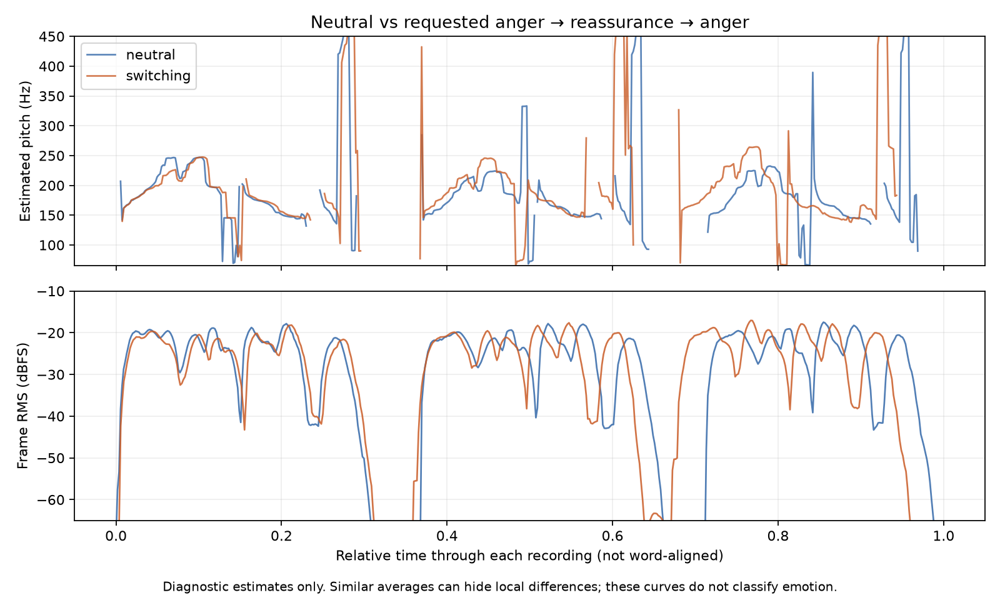

In [12]:
from IPython.display import Image
print(json.loads((STUDY/'opposite-tones-acoustic-comparison.json').read_text()))
display(Image(filename=str(STUDY/'opposite-tones-contours.png')))

## Consolidated experiment record and findings to date

This section distinguishes technical execution, the user's listening observations, and interpretations. It does not replace the original recordings or retroactively turn unscored trials into successful acting demonstrations.

| Experiment | What changed / what stayed fixed | Established outcome | Listening outcome and limit |
|---|---|---|---|
| Initial 32-take audition pilot | Two engines, two speakers, two texts, four requested styles. VoxCPM2: fixed neutral reference plus written direction. F5: same-speaker expressive references. | All planned takes generated and passed technical checks; matched listening copies preserved. | The user reported mood differentiation but found the acting inadequate. No complete per-take ratings or word/identity verification were recorded. |
| Short relief/disbelief reference | New line: “You came back. I thought I'd lost you.” VoxCPM2, existing male neutral reference, seed 7, 10 steps, written direction requesting relief and disbelief. | 3.04-second real generated recording; not captured live-assistant audio and not downloaded media. | The user described it as better. This is encouraging feedback on one take, not proof of reliable emotion control. |
| Dynamic passage | One continuous call; distinct sentences and semantic cues paired with directions for urgency, pleading, recognition, hurt and relief. Same engine, reference, seed and step count as subsequent switching test. | 11.36-second recording. No sentence splicing or manual acting edits. | No explicit detailed listener rating was recorded. The content and punctuation themselves suggest an emotional arc, so this is not an isolated test of instruction control. |
| Opposite-tone neutral control | “I need you to stay right here.” repeated three times, neutral direction, same engine/reference/seed/steps. | 5.44-second recording. | Comparison control; exact repetition delivery remains unverified by transcription. |
| Opposite-tone directed take | Identical repeated words; requested controlled anger → tender reassurance → controlled anger in one call. | 5.28-second recording. Both conditions statically matched to −23 LUFS, with no compression or segment splicing. | The user reported the neutral and directed takes sounded the same. This experiment did not demonstrate useful within-passage emotional switching. |
| File and embedding audit | Compared saved files, byte contents and the notebook's embedded audio payloads. | Two distinct recordings with different durations and hashes; notebook payloads match the intended separate files. | Rules out a saved-file/notebook overwrite or duplicate embedding. It does not independently verify delivery through the live voice-chat player. |
| Acoustic comparison | Same two matched files; duration, amplitude-gated Yin pitch, RMS dynamics, waveform correlation and aligned MFCC features. | Neutral vs directed: duration 5.44/5.28 s; median pitch 174.9/181.6 Hz; pitch IQR 55.1/58.0 Hz; active-frame RMS spread 11.27/11.79 dB. | Modest overall differences and broadly similar contours are consistent with weak perceived contrast. These diagnostics do not classify emotions or independently prove absence of every local delivery difference. |

### Why the two continuous-passage tests differ
The generation mechanism did not change: one native VoxCPM2 API request with raw application effects, a fixed existing voice reference and written delivery instructions. The dynamic passage used different sentences, emotion-bearing meanings, punctuation and sentence-specific direction. The opposite-tone test held the words identical, placing more of the burden on instruction-following alone. The first cannot be treated as independent proof of a notation-based performance controller.

### Findings supported now
1. We can generate local, source-traceable speech and direct it through written instructions and/or references. The existence of these controls is established; reliable obedience to them is not.
2. The short relief sample received positive comparative feedback from the user. That result is local to one example.
3. The identical-word switching experiment failed to demonstrate the intended perceptual contrast for this listener. Successful API calls, distinct hashes and small signal differences do not override that outcome.
4. There is no evidence here that the arrow notation itself is parsed as a formal acting language. It is a human-readable summary; actual conditioning was prose.
5. Mastering was not used to manufacture acting differences in these tests. The comparison gain was static and preserves internal dynamics. Better technical audio quality and better acting remain separate goals.

### What remains unresolved
We have not shown reliable phrase-level emotion trajectories, recognizable anger-versus-reassurance contrast on demand, speaker identity continuity, exact text preservation, transfer of an externally supplied performance to new words, seed robustness or a superior model. No YouTube/podcast recording or live-assistant audio was captured for these experiments. No performance-transfer engine was installed or tested. The current evidence does not justify collecting a large reference library or replacing the approved production voice.

### Next discriminating experiment — proposed, not executed
Generate the identical sentence independently under neutral, controlled-anger and tender-reassurance directions, keeping the reference and sampling settings fixed. Audition the isolated lines before joining them. This separates the ability to produce contrasting single-line deliveries from the ability to switch within a continuous passage. If isolated contrast also fails, evaluate a verified performance-transfer/voice-conversion mechanism with an appropriate performed source; do not treat additional elaborate global directions as an established fix.

The current record is an exploratory study with one listener's qualitative feedback. There is no blinded listening panel, automatic emotion validation, independently verified transcript alignment or statistical significance claim.


## Independent single-line direction: neutral, anger, reassurance

### Hypothesis and discriminating question
The failed continuous-switching test could reflect difficulty changing delivery within one passage, weak single-line instruction control, or both. This experiment removes the switching requirement. Can three independent generations of the identical line produce convincing neutral, controlled-anger and tender-reassurance deliveries while preserving the speaker and words?

### Controls and execution
Each take says “I need you to stay right here.” Full VoxCPM2, the same existing male neutral reference and transcript, seed 7, 10 steps, raw application effects and all other submitted controls are fixed. An automated comparison of saved requests confirms that **only the instruction differs**. The takes were generated serially in fixed order; cold/warm and order effects prevent a speed ranking. There is one seed and one line, with no selective retakes.

All three calls returned non-silent finite 48 kHz WAVs, each 1.76 seconds long. Their contents and hashes differ. Static gain matched the listening copies to −23 LUFS without compression, enhancement or splicing. Originals are preserved. Three request envelopes and sampled sidecar model-device evidence were recorded; the device sample is cumulative process-level observation rather than a per-take memory peak.

### Descriptive findings
Estimated median pitch is approximately 164.6 Hz for neutral, 156.5 Hz for controlled anger and 141.4 Hz for reassurance; estimated pitch IQR is 48.7, 46.8 and 45.5 Hz respectively. These amplitude-gated Yin estimates may contain octave errors. Different pitch is not proof of emotion, naturalness, speaker continuity or word accuracy. There is no listener assessment of these new takes yet.

### Decision remains conditional
Listen to the three isolated takes before assembling anything. If the requested contrast is clear, believable and preserves words and identity, a per-line generation workflow is a candidate for later testing. If they still sound alike, this experiment gives no basis for claiming useful direction control; investigate another performance-control mechanism. No successful switching sequence has been assembled or claimed.


In [13]:
isolated = json.loads((STUDY/'isolated-tones-analysis.json').read_text())
print('Only request difference:', isolated['only_request_difference'])
for take in isolated['conditions']:
    print('REQUESTED:', take['condition'].replace('-',' '))
    print('Duration:', take['duration_seconds'], 'seconds; API time:', round(take['api_seconds'],2), 'seconds')
    display(Audio(filename=take['matched_path']))

Only request difference: instruct
REQUESTED: neutral
Duration: 1.76 seconds; API time: 12.26 seconds


REQUESTED: controlled anger
Duration: 1.76 seconds; API time: 1.85 seconds


REQUESTED: tender reassurance
Duration: 1.76 seconds; API time: 1.79 seconds


### Reproduce with fresh take names
The function below performs real generation when invoked. Choose a fresh prefix; existing take directories are intentionally never overwritten. It reads the exact saved requests and verifies each reference hash before use. Opening or running the notebook's display cells does not silently regenerate audio.


In [14]:
def reproduce_isolated_tones(prefix):
    import importlib.util, hashlib
    spec = importlib.util.spec_from_file_location('paper15_api', STUDY/'api_experiment.py')
    api = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(api)
    results = []
    for take in isolated['conditions']:
        req = take['request']
        reference = Path(req['reference']['path'])
        assert hashlib.sha256(reference.read_bytes()).hexdigest() == req['reference']['sha256']
        results.append(api.generate(prefix+'-'+take['condition'], req['text'], engine=req['engine'],
            instruct=req['instruct'], seed=int(req['seed']), ref_audio=str(reference),
            ref_text=req['ref_text'], num_step=int(req['num_step'])))
    return results
# Explicitly run with fresh names only when desired:
# reproduce_isolated_tones('isolated-new-pilot')

## Reference-guided continuation: neutral versus expressive source

### Prior listening result and hypothesis
The user reported that the isolated neutral and reassuring takes did not differ much. Separating sentences therefore did not establish that particular written-direction contrast. This next experiment changes the **reference recording**, removes written emotion instructions, and explicitly tests the native continuation mode.

Hypothesis: the same speaker's expressive reference may guide delivery more strongly than a neutral reference when reference audio and its transcript are provided as continuation context. The listening question is whether the resulting contrast is believable and preserves the target words and speaker—not merely whether pitch changes.

### Controls and mode verification
The target words remain “I need you to stay right here.” Both references belong to the existing male speaker: neutral versus anger. Their **catalog transcripts are identical**, so no reference-transcript wording changes between these requests. This is transcript metadata, not a new independent transcription audit. Reference durations differ (about 5.41 and 5.86 seconds before adapter preparation), as do their acoustic performance properties. The adapter trims reference silence, which is not independently controlled here.

Both requests use full VoxCPM2, seed 7, 10 steps and raw application effects. Neither contains a written instruction or inline instruction prefix. Saved-request comparison confirms equality except for the reference path/hash. Direct inspection and evaluation of the pinned native adapter's mapping confirms both use reference waveform + prompt waveform + prompt transcript: **audio-continuation mode**.

This mode differs from the earlier instruction-conditioned tests, where a nonempty instruction disabled transcript continuation. Therefore comparisons across the old and new experiments cannot attribute every difference to reference selection alone. Within this new pair, mode is held fixed.

### Measured output and limits
Both real API calls returned 2.40-second, finite, non-silent 48 kHz WAVs. Static-gain copies are matched to −23 LUFS. Estimated median pitch is about 153.5 Hz with the neutral reference and 280.4 Hz with the angry reference; pitch IQR is about 26.5 and 98.3 Hz. This is a substantial descriptive pitch change under fixed continuation-mode settings. It is **not** an automatic emotion, identity, exact-word or quality score; amplitude-gated Yin estimates can contain octave errors.

The experiment establishes a measurable reference-conditioned acoustic difference in this example. Whether it is a useful acting improvement is unscored pending listening. Reference intensity, timing, timbre and other acoustic properties remain intertwined. One speaker, one target line and one seed do not establish general reliability. No new model, downloaded voice sample or performance-transfer system was introduced, and the approved production standard is unchanged.


In [15]:
reference_test = json.loads((STUDY/'reference-guidance-analysis.json').read_text())
print('Controls equal except reference:', reference_test['controls_equal_except_reference'])
print('Reference catalog transcripts equal:', reference_test['reference_transcripts_equal'])
for take in reference_test['conditions']:
    print(take['condition'].replace('-',' '), '| mode:', take['effective_mode'])
    display(Audio(filename=take['matched_path']))

Controls equal except reference: True
Reference catalog transcripts equal: True
neutral reference | mode: audio-continuation


angry reference | mode: audio-continuation


### Reproduce or inspect the input references
Choose a fresh prefix for new generations. The reproduction function intentionally sends no written emotion direction; providing the reference transcript activates the verified continuation path. The optional reference-playback function lets the reader hear the source clips at their original levels; those input clips are not loudness-matched comparison outputs.


In [16]:
def reproduce_reference_guidance(prefix):
    import importlib.util, hashlib
    spec = importlib.util.spec_from_file_location('reference_api', STUDY/'api_experiment.py')
    api = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(api)
    results = []
    for take in reference_test['conditions']:
        req = take['request']
        reference = Path(req['reference']['path'])
        assert hashlib.sha256(reference.read_bytes()).hexdigest() == req['reference']['sha256']
        assert 'instruct' not in req
        results.append(api.generate(prefix+'-'+take['condition'], req['text'], engine=req['engine'],
            instruct=None, seed=int(req['seed']), ref_audio=str(reference),
            ref_text=req['ref_text'], num_step=int(req['num_step'])))
    return results

def listen_to_reference_inputs():
    for take in reference_test['conditions']:
        print('INPUT REFERENCE:', take['condition'])
        display(Audio(filename=take['request']['reference']['path']))
# Optional, explicit actions:
# reproduce_reference_guidance('reference-new-test')
# listen_to_reference_inputs()